# Stromblick: the analysis in one place

This notebook walks through the project as a data science piece: the data, the baselines, the model, how its error behaves, what it relies on, how honest its uncertainty is, and where it falls short. It does not train anything. Everything is read from artifacts the repo already commits (the SMARD snapshot, the weekly benchmark, and the dated studies under `reports/`), so it runs in seconds and matches the README.

To rerun: `pip install -e ".[dev,notebook]"`, then from the repo root `jupyter nbconvert --to notebook --execute --inplace notebooks/analysis.ipynb`.

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
from energy_forecast.features import FEATURE_COLUMNS, add_features  # noqa: E402
from energy_forecast.theme import BLUE, GREEN, INK, MUTED, ORANGE, style_axes  # noqa: E402

REPORTS = ROOT / "reports"


def load(name):
    return json.loads((REPORTS / f"{name}.json").read_text())


plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (9, 3.6)})
pd.options.display.float_format = "{:,.1f}".format

## 1. The data

Hourly total grid load for Germany (SMARD module 410, published by the Bundesnetzagentur). The committed snapshot holds three years; the model trains on the latest two. Every refresh passes a quality gate before it is written. Errors (schema, duplicates, UTC ordering, implausible values) stop the refresh; gaps and NaNs are reported as warnings and never imputed.

In [2]:
demand = pd.read_csv("data/clean/demand_hourly.csv")
demand["timestamp"] = pd.to_datetime(demand.timestamp, utc=True)
meta = json.loads(Path("data/clean/metadata.json").read_text())
first, last = demand.timestamp.min(), demand.timestamp.max()
print(f"{len(demand):,} hours, {first:%Y-%m-%d} to {last:%Y-%m-%d}")
pd.DataFrame(meta["quality"]["checks"])[["name", "severity", "passed", "detail"]]

26,219 hours, 2023-11-26 to 2026-11-23


,name,severity,passed,detail
0,schema,error,True,timestamp and demand_mw present
1,non_empty,error,True,"26,219 rows"
2,timezone_aware_utc,error,True,timestamps must be tz-aware UTC before they cr...
3,chronological,error,True,timestamps must be sorted ascending
4,unique_timestamps,error,True,no duplicates
5,has_observations,error,True,"26,219 observed hours"
6,plausible_range,error,True,"0 value(s) outside 20,000-100,000 MW (observed..."
7,positive_demand,error,True,0 non-positive value(s)
8,nan_fraction,warning,True,0.00% of hours indexed but unpublished (limit 5%)
9,hourly_continuity,warning,True,"0 missing hourly timestamp(s), 0.00% of the ex..."


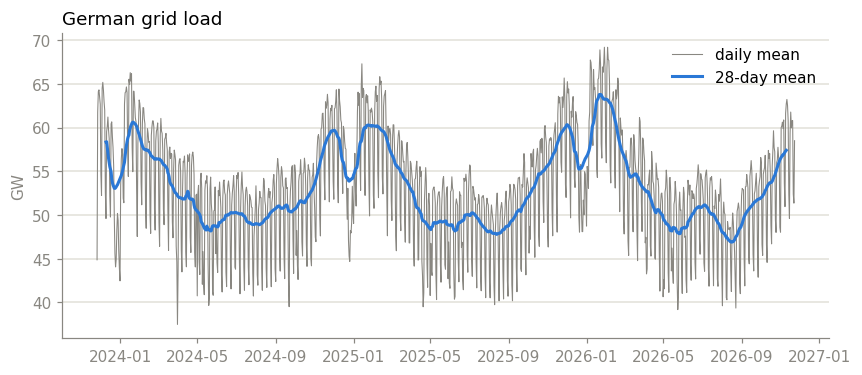

In [3]:
daily = demand.set_index("timestamp").demand_mw.resample("D").mean() / 1000
fig, ax = plt.subplots()
ax.plot(daily.index, daily, color=MUTED, linewidth=0.7, label="daily mean")
ax.plot(daily.index, daily.rolling(28, center=True).mean(), color=BLUE, linewidth=2,
        label="28-day mean")
ax.set_ylabel("GW")
ax.set_title("German grid load", loc="left")
ax.legend(frameon=False)
style_axes(ax)

Two cycles dominate: winter sits well above summer, and every week has a weekday plateau and a weekend dip. The sharp drops around late December are the Christmas holidays, which is also where the model struggles most.

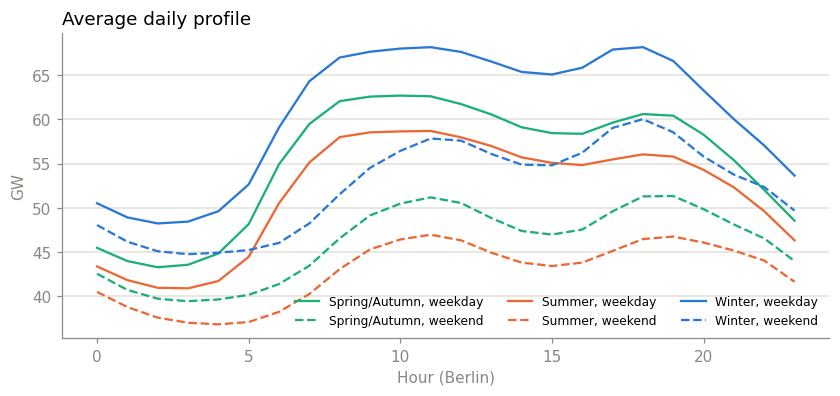

In [4]:
local = demand.assign(local=demand.timestamp.dt.tz_convert("Europe/Berlin"))
local["hour"] = local.local.dt.hour
local["day"] = np.where(local.local.dt.weekday >= 5, "Weekend", "Weekday")
month = local.local.dt.month
local["season"] = np.select([month.isin([12, 1, 2]), month.isin([6, 7, 8])], ["Winter", "Summer"],
                            "Spring/Autumn")
profile = (local.groupby(["season", "day", "hour"]).demand_mw.mean().div(1000)
           .unstack(["season", "day"]))
fig, ax = plt.subplots()
colors = {"Winter": BLUE, "Spring/Autumn": GREEN, "Summer": ORANGE}
for (season, day), series in profile.items():
    ax.plot(series.index, series, color=colors[season], linestyle="-" if day == "Weekday" else "--",
            label=f"{season}, {day.lower()}")
ax.set_xlabel("Hour (Berlin)")
ax.set_ylabel("GW")
ax.set_title("Average daily profile", loc="left")
ax.legend(frameon=False, fontsize=8, ncol=3)
style_axes(ax)

## 2. Features that cannot see the future

The model uses the calendar plus lagged and rolling demand. Every lag and rolling window is shifted by one hour before it is aggregated, so no row can see its own value. The cell below checks that on real data: change the demand at one hour, and the features of that hour and every earlier hour must not move.

In [5]:
frame = demand.tail(24 * 10).reset_index(drop=True)
before = add_features(frame)
tampered = frame.copy()
t = len(frame) - 30
tampered.loc[t, "demand_mw"] += 1e6
after = add_features(tampered)
same = np.allclose(before.loc[:t, FEATURE_COLUMNS].fillna(0),
                   after.loc[:t, FEATURE_COLUMNS].fillna(0))
print("features up to and including the changed hour unchanged:", same)
changed = before.loc[t + 1, FEATURE_COLUMNS] != after.loc[t + 1, FEATURE_COLUMNS]
print("features that react one hour later:", list(changed[changed].index))

features up to and including the changed hour unchanged: True
features that react one hour later: ['lag_1h', 'rolling_24h_mean', 'rolling_7d_mean']


## 3. Baselines and the champion

Three models, scored on the same walk-forward backtest: one forecast origin per day over the latest year, a refit at every origin, and the next 24 hours scored. Never a random split. The seasonal-naive baseline ("same hour yesterday") is the floor any model has to clear.

In [6]:
bench = load("benchmark_summary")
metrics = pd.read_csv(REPORTS / "benchmark_metrics.csv")
metrics["origin"] = pd.to_datetime(metrics.origin, utc=True)
table = pd.DataFrame(bench["models"]).T[["mae_mean", "rmse_mean", "smape_mean"]]
table.columns = ["MAE (MW)", "RMSE (MW)", "sMAPE (%)"]
print(f"{bench['origins']} origins, {bench['eval_start'][:10]} to {bench['eval_end'][:10]}, "
      f"model {bench['model_version']}")
table.sort_values("MAE (MW)")

366 origins, 2025-11-22 to 2026-11-23, model v2


,MAE (MW),RMSE (MW),sMAPE (%)
HistGradientBoosting,"1,505.3","1,826.1",2.9
SARIMAX,"3,704.1","4,642.0",7.2
Seasonal naive,"3,892.8","4,914.6",7.4


In [7]:
sig = pd.DataFrame(bench["significance"]["comparisons"]).T
sig = sig[["mean_diff", "ci_lower", "ci_upper", "wilcoxon_p", "dm_p_value"]]
sig.columns = ["champion minus rival (MW)", "CI low", "CI high", "Wilcoxon p", "Diebold-Mariano p"]
sig.style.format({c: "{:+,.0f}" for c in sig.columns[:3]} | {c: "{:.1e}" for c in sig.columns[3:]})

,champion minus rival (MW),CI low,CI high,Wilcoxon p,Diebold-Mariano p
Seasonal naive,"-2,387","-2,632","-2,142",9.8e-42,4.9e-47
SARIMAX,"-2,199","-2,444","-1,959",1.4e-42,1.1e-52


The gap is tested per origin, not per hour: the 24 hours of one forecast share the same weather and demand level, so treating them as independent would overstate confidence. The paired bootstrap CI and the Wilcoxon test use one value per origin. The Diebold-Mariano test uses hourly losses but corrects for the autocorrelation a 24-step forecast creates.

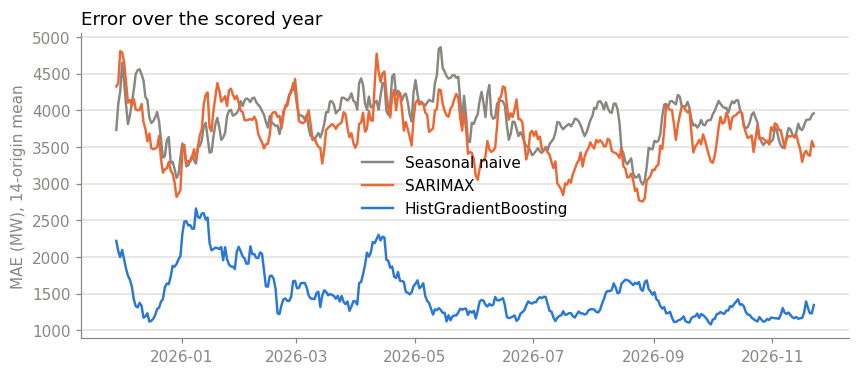

In [8]:
wide = metrics.pivot(index="origin", columns="model", values="mae")
fig, ax = plt.subplots()
models = [("Seasonal naive", MUTED), ("SARIMAX", ORANGE), ("HistGradientBoosting", BLUE)]
for model, color in models:
    ax.plot(wide.index, wide[model].rolling(14, min_periods=7).mean(), color=color, label=model,
            linewidth=1.6)
ax.set_ylabel("MAE (MW), 14-origin mean")
ax.set_title("Error over the scored year", loc="left")
ax.legend(frameon=False)
style_axes(ax)

## 4. How error grows with the horizon

The champion forecasts recursively: each hour's prediction becomes the next hour's `lag_1h`. So an early miss is carried forward, and error should grow with the horizon. The benchmark's hourly predictions show by how much.

,MAE,p95
step,,
1,590.7,"1,590.5"
6,"1,327.6","3,554.0"
12,"1,424.2","3,613.8"
18,"1,643.5","4,333.5"
24,"2,164.8","5,442.7"


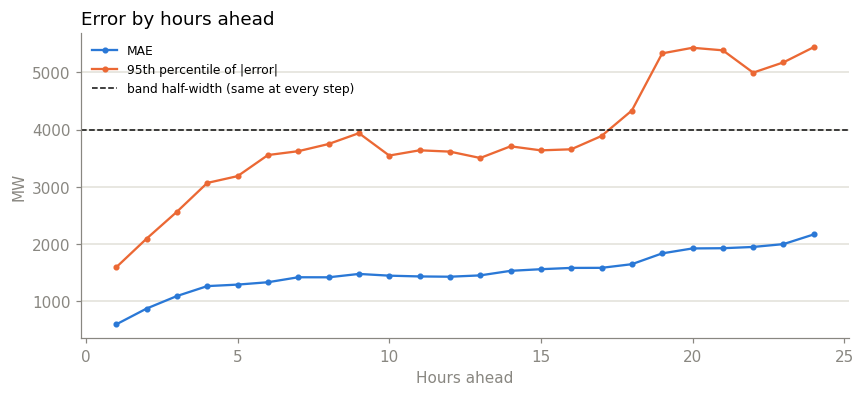

In [9]:
champion = pd.read_csv(REPORTS / "benchmark_champion_hourly.csv")
for column in ("origin", "timestamp"):
    champion[column] = pd.to_datetime(champion[column], utc=True)
champion["step"] = ((champion.timestamp - champion.origin) / pd.Timedelta(hours=1)).astype(int)
champion["abs_error"] = (champion.predicted - champion.demand_mw).abs()
by_step = champion.groupby("step").abs_error.agg(MAE="mean", p95=lambda s: s.quantile(0.95))
half_width = bench["interval_coverage"]["mean_band_mw"] / 2

fig, ax = plt.subplots()
ax.plot(by_step.index, by_step.MAE, color=BLUE, marker="o", markersize=3, label="MAE")
ax.plot(by_step.index, by_step.p95, color=ORANGE, marker="o", markersize=3,
        label="95th percentile of |error|")
ax.axhline(half_width, color=INK, linestyle="--", linewidth=1,
           label="band half-width (same at every step)")
ax.set_xlabel("Hours ahead")
ax.set_ylabel("MW")
ax.set_title("Error by hours ahead", loc="left")
ax.legend(frameon=False, fontsize=8)
style_axes(ax)
by_step.iloc[[0, 5, 11, 17, 23]]

The orange line is how wide a 95% band would need to be at each step; the dashed line is the shipped band. One width for every horizon means the band is too wide for the first hours and too narrow for the last ones. Averaged over the day it comes out about right, which is what the coverage test in section 6 measures.

## 5. What the model relies on

Permutation importance in the benchmark shuffles features on rows whose lags are observed, i.e. one step ahead. The served forecast is recursive, so `scripts/explain.py` computes exact TreeSHAP values on the feature rows the model actually predicted from at every benchmark origin, and splits them by hours ahead.

In [10]:
explain = load("explainability_summary")
importance = pd.DataFrame({
    "mean |SHAP| at forecast time (MW)": explain["mean_abs_shap_mw"],
    "permutation, one step ahead (MW)": explain["permutation_importance_mw"],
}).sort_values("mean |SHAP| at forecast time (MW)", ascending=False)
importance

,mean |SHAP| at forecast time (MW),"permutation, one step ahead (MW)"
lag_1h,"7,406.8","8,775.2"
hour,"1,328.6","1,800.7"
lag_168h,273.8,92.1
weekday,180.8,144.2
lag_24h,149.0,32.8
month,82.0,0.0
rolling_7d_mean,47.6,0.2
rolling_24h_mean,39.5,-11.9
is_public_holiday,24.1,0.0
is_weekend,0.2,0.0


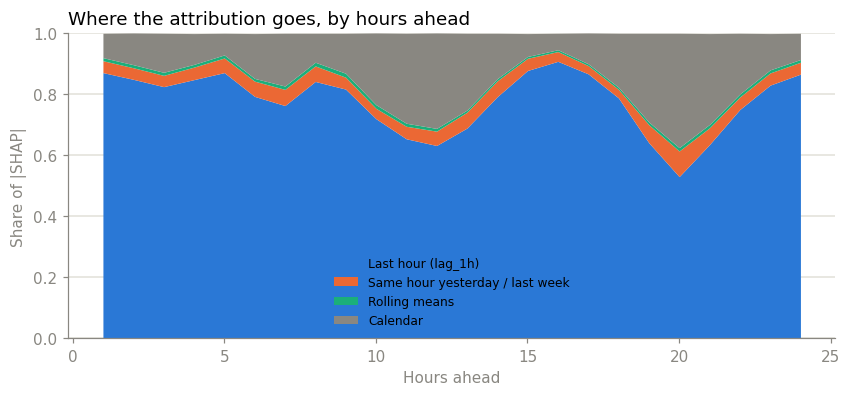

In [11]:
shares = pd.DataFrame(explain["group_share_by_step"]).T
shares.index = shares.index.astype(int)
ax = shares.sort_index().plot.area(color=[BLUE, ORANGE, GREEN, MUTED], linewidth=0,
                                   figsize=(9, 3.6))
ax.set_xlabel("Hours ahead")
ax.set_ylabel("Share of |SHAP|")
ax.set_ylim(0, 1)
ax.set_title("Where the attribution goes, by hours ahead", loc="left")
ax.legend(frameon=False, fontsize=8)
style_axes(ax)

All benchmark origins are at 09:00 UTC, so hours ahead and time of day move together. The calendar share rising mid-horizon is mostly the evening and night hours, where the daily shape matters most. What does read as a horizon effect is that `lag_1h`, which is the model's own output from step 2 on, still carries most of the attribution at 24 hours ahead while the error is more than three times its one-hour level.

In [12]:
h = explain["holidays"]
print(f"On {h['hours']:,} holiday hours the holiday flag moves the forecast by "
      f"{h['mean_holiday_shap_mw']:+,.0f} MW, and the forecast still ends up "
      f"{h['mean_error_mw']:+,.0f} MW off on average "
      f"({h['mean_error_other_mw']:+,.0f} MW on other hours).")

On 216 holiday hours the holiday flag moves the forecast by -352 MW, and the forecast still ends up +801 MW off on average (-97 MW on other hours).


## 6. Uncertainty: is the 95% band really 95%?

The band is split conformal: its half-width is a rank statistic of the absolute errors of the last 28 daily forecasts. An interval study compared six recipes on the latest year under a rule fixed before the run (the coverage CI must contain 95%, and the interval score must beat the old band).

In [13]:
intervals = load("interval_study_summary")
iv = pd.DataFrame(intervals["means"]).T
iv["coverage"] *= 100
iv.columns = ["coverage (%)", "mean width (MW)", "interval score (lower is better)"]
iv.sort_values("interval score (lower is better)")

,coverage (%),mean width (MW),interval score (lower is better)
Conformalized quantile (CQR),94.6,"8,655.7","11,206.9"
Split conformal (28 origins),94.4,"7,947.5","11,438.7"
Benchmark recipe (7 origins),93.5,"8,043.4","11,661.9"
Adaptive conformal,94.9,"8,756.6","11,720.8"
Shipped (168h validation week),96.8,"10,847.0","12,808.7"
Quantile GBM,58.9,"3,595.2","24,367.5"


The old band was too wide and over-covered. The quantile GBM on its own under-covers badly, which is why it needs conformal calibration. CQR scored best on the mean, but it could not be separated from split conformal and needs two extra models in the serving path, so the simpler split-conformal band shipped. The weekly benchmark scores the same recipe:

In [14]:
cov = bench["significance"]["coverage"]
print(f"Benchmark coverage {cov['mean_coverage']:.1%} (95% CI {cov['ci_lower']:.1%} to "
      f"{cov['ci_upper']:.1%}) against a nominal {cov['nominal']:.0%}, p = {cov['p_value']:.2f} "
      f"over {cov['n_origins']:.0f} origins")

Benchmark coverage 94.3% (95% CI 93.1% to 95.5%) against a nominal 95%, p = 0.26 over 338 origins


## 7. Three questions, each with a rule fixed first

Each study wrote its decision rule down before the run: per-origin (or per-day) paired differences, a bootstrap CI and a Wilcoxon test, Holm-corrected across the comparisons. Something counts as better only if the CI excludes zero and the corrected p is under 0.05.

In [15]:
def comparison_frame(results, label):
    rows = {name: {"difference (MW)": r["mean_diff"], "CI low": r["ci_lower"],
                   "CI high": r["ci_upper"], "Holm p": r["holm_p"]} for name, r in results.items()}
    frame = pd.DataFrame(rows).T
    frame.index = pd.MultiIndex.from_product([[label], frame.index])
    return frame


studies = pd.concat([
    comparison_frame(load("window_study_summary")["comparisons"], "Training window vs 1 year"),
    comparison_frame(load("tso_study_summary")["comparisons"], "Model vs grid operators"),
    comparison_frame(load("weather_study_summary")["comparisons"], "Temperature vs no weather"),
])
studies.style.format({"difference (MW)": "{:+,.0f}", "CI low": "{:+,.0f}", "CI high": "{:+,.0f}",
                      "Holm p": "{:.3f}"})

Reading the table (negative is better for the first-named side):

- **Training window.** Two years beat one, so the model now trains on two. Five years had a slightly lower mean but missed the corrected threshold, so picking it would have meant choosing after seeing the result.
- **Grid operators.** With data this project cannot get, the model would beat the operators' published day-ahead forecast. With SMARD's real publication lag it is a statistical tie. A fixed 50/50 average of the two beats the operators, because the two make different mistakes.
- **Temperature.** Not even observed weather clears the bar at a 24-hour horizon: yesterday's load at the same hour was drawn under nearly the same weather, and the lags already carry it.

Each study has its own report under `reports/` with the design, the season and holiday breakdowns, and the caveats.

## 8. Limits

- **Holidays** are the weakest slice in every study. With two years of training data each holiday has been seen at most twice, and the holiday flag corrects only part of the drop (section 5).
- **The band** has one width for every horizon (section 4), so it is calibrated on average, not hour by hour. A horizon-aware band is the natural next step.
- **Data latency** costs more than model choice: against the operators, the gap between fresh data and SMARD's lag is larger than any modelling gain measured here.
- **One national series.** No regional breakdown, no price or generation inputs, and the 2022-23 drop in demand means older history describes a level the grid no longer runs at.